<a href="https://colab.research.google.com/github/Pradeep752007/qskill-python-internship/blob/main/Task1_Pandas_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

========== ORIGINAL DATASET ==========
   Student  Gender  Study_Hours  Attendance_Percent  Previous_Score  \
0     Arun    Male            2                  75            60.0   
1      Anu  Female            4                  85            70.0   
2    Rahul    Male            3                  80            65.0   
3    Meera  Female            6                  95            82.0   
4   Vishnu    Male            5                  90            78.0   
5     Diya  Female            7                  96            88.0   
6    Kiran    Male            1                  65            50.0   
7     Neha  Female            5                  88            75.0   
8    Akhil    Male            4                  82            70.0   
9    Sneha  Female            8                  98            90.0   
10    Ravi    Male            3                  78             NaN   
11   Priya  Female            6                  92            85.0   

    Final_Score  
0          62.0  
1

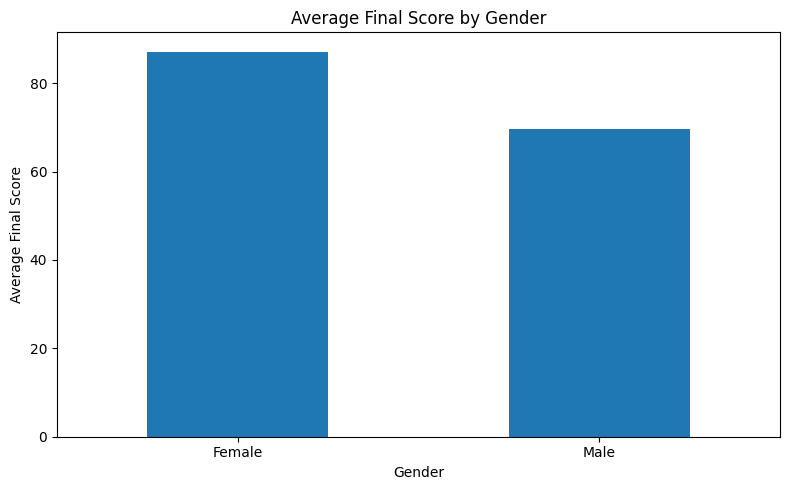

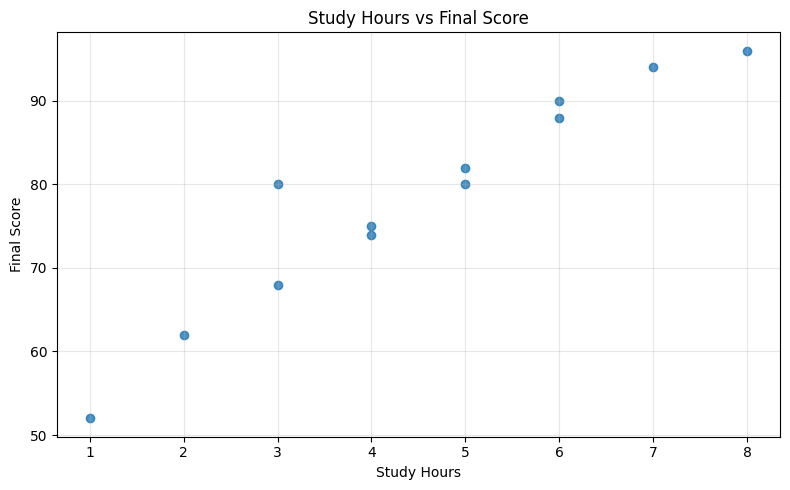

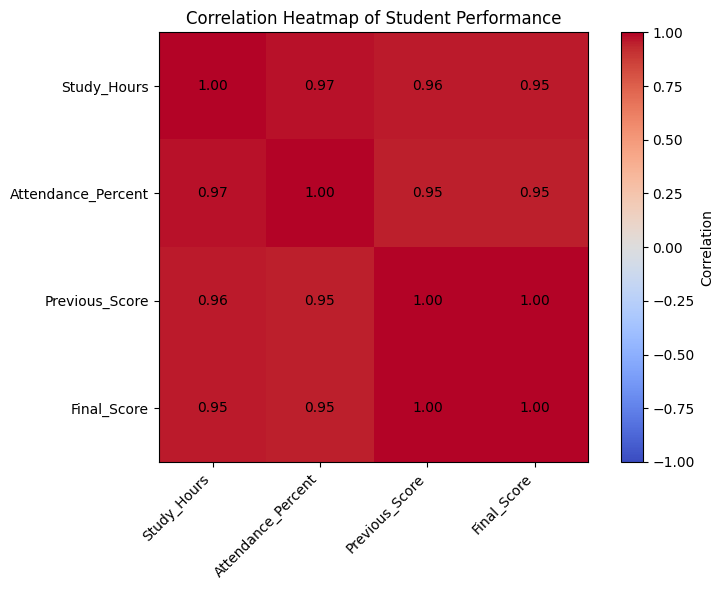


========== INSIGHTS AND OBSERVATIONS ==========
1. The average final score is 78.42.
2. The average study time is 4.50 hours.
3. Female students have the higher average score in this sample.
4. The correlation between study hours and final score is 0.95.
   The data shows a positive association between study hours and final scores.

========== ANALYSIS COMPLETED ==========


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# 1. LOAD THE CSV FILE
# ==================================================

df = pd.read_csv("student_performance.csv")

print("========== ORIGINAL DATASET ==========")
print(df)

# ==================================================
# 2. EXPLORE THE DATASET
# ==================================================

print("\n========== FIRST FIVE ROWS ==========")
print(df.head())

print("\n========== DATASET INFORMATION ==========")
df.info()

print("\n========== DATASET SHAPE ==========")
print("Rows and columns:", df.shape)

print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

# ==================================================
# 3. DATA CLEANING
# ==================================================

# Fill missing numerical values with column medians.
numeric_columns = [
    "Study_Hours",
    "Attendance_Percent",
    "Previous_Score",
    "Final_Score"
]

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

# Remove duplicate records, if any.
df = df.drop_duplicates()

print("\n========== CLEANED DATASET ==========")
print(df)

print("\n========== MISSING VALUES AFTER CLEANING ==========")
print(df.isnull().sum())

# ==================================================
# 4. SELECTION
# ==================================================

print("\n========== SELECT FINAL SCORES ==========")
print(df["Final_Score"])

print("\n========== SELECT MULTIPLE COLUMNS ==========")
print(df[["Student", "Study_Hours", "Final_Score"]])

# ==================================================
# 5. FILTERING
# ==================================================

print("\n========== STUDENTS SCORING ABOVE 80 ==========")
high_scorers = df[df["Final_Score"] > 80]
print(high_scorers[["Student", "Final_Score"]])

print("\n========== STUDENTS STUDYING AT LEAST 5 HOURS ==========")
regular_studiers = df[df["Study_Hours"] >= 5]
print(regular_studiers[["Student", "Study_Hours", "Final_Score"]])

# ==================================================
# 6. AGGREGATION AND STATISTICS
# ==================================================

print("\n========== NUMERICAL SUMMARY ==========")
print(df[numeric_columns].describe())

average_score = df["Final_Score"].mean()
highest_score = df["Final_Score"].max()
lowest_score = df["Final_Score"].min()
average_study_hours = df["Study_Hours"].mean()

print("\nAverage final score:", round(average_score, 2))
print("Highest final score:", highest_score)
print("Lowest final score:", lowest_score)
print("Average study hours:", round(average_study_hours, 2))

print("\n========== AVERAGE SCORE BY GENDER ==========")
gender_average = df.groupby("Gender")["Final_Score"].mean()
print(gender_average.round(2))

print("\n========== AVERAGE SCORE BY STUDY HOURS ==========")
study_average = df.groupby("Study_Hours")["Final_Score"].mean()
print(study_average.round(2))

# ==================================================
# 7. BAR CHART
# Average final score by gender
# ==================================================

plt.figure(figsize=(8, 5))

gender_average.plot(kind="bar")

plt.title("Average Final Score by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Final Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ==================================================
# 8. SCATTER PLOT
# Study hours vs final score
# ==================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Study_Hours"],
    df["Final_Score"],
    alpha=0.8
)

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ==================================================
# 9. HEATMAP
# Correlation between numerical variables
# ==================================================

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

image = plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(image, label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

# Display correlation values in each cell.
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j,
            i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Heatmap of Student Performance")
plt.tight_layout()
plt.show()

# ==================================================
# 10. AUTOMATIC OBSERVATIONS
# ==================================================

study_score_correlation = df[
    ["Study_Hours", "Final_Score"]
].corr().iloc[0, 1]

best_gender = gender_average.idxmax()

print("\n========== INSIGHTS AND OBSERVATIONS ==========")

print(
    f"1. The average final score is {average_score:.2f}."
)

print(
    f"2. The average study time is {average_study_hours:.2f} hours."
)

print(
    f"3. {best_gender} students have the higher average score "
    f"in this sample."
)

print(
    "4. The correlation between study hours and final score is "
    f"{study_score_correlation:.2f}."
)

if study_score_correlation > 0:
    print(
        "   The data shows a positive association between study "
        "hours and final scores."
    )
elif study_score_correlation < 0:
    print(
        "   The data shows a negative association between study "
        "hours and final scores."
    )
else:
    print(
        "   The data shows no linear association between study "
        "hours and final scores."
    )

print("\n========== ANALYSIS COMPLETED ==========")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')